<a href="https://colab.research.google.com/github/Madihasafi/ITC-300-Data-Visualization-/blob/main/Madiha_Safi%2C_w13p2_Visualizing_Multi_Dimensional_Relationships_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **ITC 300: Data Visualization**
## **w13p2 Visualizing Multi-Dimensional Relationships - Assignment**


## **Assignment purpose**

This assignment assesses your ability to prepare data and visualize relationships among several variables in Google Colab. You will use the `Salaries.csv` dataset to create and interpret:

- a matrix scatterplot;
- a trellis plot;
- a bubble plot;
- a contour plot based on a fitted regression model.

You must write the code, display the results, and answer the interpretation questions in your own words.


## **Learning outcomes**

After completing the assignment, you should be able to:

- prepare numerical and categorical variables for visualization;
- create multidimensional charts with Pandas, Seaborn, and Matplotlib;
- encode variables through position, color, marker area, panels, and contours;
- interpret patterns while considering overlap, unequal group sizes, and data coverage;
- evaluate the limits of a fitted prediction surface;
- distinguish association from causation.


## **Dataset**

Use the provided `Salaries.csv` file.

| Variable | Description |
|---|---|
| `rank` | Academic rank |
| `discipline` | Discipline A or B |
| `yrs.since.phd` | Years since receiving the PhD |
| `yrs.service` | Years of service |
| `sex` | Recorded sex category |
| `salary` | Annual salary |
| `Unnamed: 0` | Exported row identifier that must be removed |


## **General instructions**

1. Complete every code cell marked `TODO`.
2. Run the notebook from top to bottom.
3. Keep all tables, charts, and numerical results visible.
4. Add titles, axis labels, and legends to every chart.
5. Write each interpretation in the Markdown answer area provided.
6. Do not claim that an observed association proves causation.
7. Submit the completed notebook as an `.ipynb` file.


# **Task 1: Import libraries and load the dataset — 10 points**

Import:

- Pandas as `pd`;
- NumPy as `np`;
- Matplotlib `pyplot` as `plt`;
- Seaborn as `sns`;
- `LinearRegression` from `sklearn.linear_model`.

Also import `Path` from `pathlib` if you use a file-upload fallback.


In [1]:
# TODO 1.1: Import the required libraries.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from pathlib import Path

sns.set_theme(style="whitegrid")

## **Load `Salaries.csv`**

Load the dataset into a DataFrame named `df`. Your solution should work in Google Colab. You may upload the file manually or use a file-upload fallback when it is not already available.


In [2]:
# TODO 1.2: Locate or upload Salaries.csv.
csv_path = Path("Salaries.csv")

# Check the current directory and common Google Colab location.
if not csv_path.exists():
    colab_path = Path("/content/Salaries.csv")
    if colab_path.exists():
        csv_path = colab_path

# If the file is not available, ask the user to upload it.
if not csv_path.exists():
    try:
        from google.colab import files

        uploaded = files.upload()

        # Find the uploaded CSV file.
        uploaded_csvs = [
            name for name in uploaded.keys()
            if name.lower().endswith(".csv")
        ]

        if not uploaded_csvs:
            raise FileNotFoundError(
                "No CSV file was uploaded. Please upload Salaries.csv."
            )

        # Prefer the required filename if it was uploaded.
        matching_file = next(
            (
                name for name in uploaded_csvs
                if Path(name).name.lower() == "salaries.csv"
            ),
            uploaded_csvs[0]
        )

        csv_path = Path(matching_file)

    except ImportError:
        raise FileNotFoundError(
            "Salaries.csv was not found. Place it in the notebook's "
            "working directory, then run this cell again."
        )

print("Dataset file:", csv_path.resolve())

Saving Salaries.csv to Salaries.csv
Dataset file: /content/Salaries.csv


In [3]:
# TODO 1.3: Read the CSV file into a DataFrame named df.
df = pd.read_csv(csv_path)

print("Dataset loaded successfully.")
print("Original dataset shape:", df.shape)

Dataset loaded successfully.
Original dataset shape: (397, 7)


## **Clean the column names**

1. Remove the exported `Unnamed: 0` column.
2. Use `errors="ignore"` so the instruction also works when the column is absent.
3. Rename:

```text
yrs.since.phd → years_since_phd
yrs.service   → years_service
```


In [4]:
# TODO 1.4: Remove the exported row identifier.
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

In [5]:
# TODO 1.5: Rename the two career variables.
df = df.rename(columns={
    "yrs.since.phd": "years_since_phd",
    "yrs.service": "years_service"
})

## **Inspect the dataset**

Display:

- the DataFrame shape;
- the first five rows;
- the data types;
- the number of missing values in each column.


In [6]:
# TODO 1.6: Display the DataFrame shape and first five rows.
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (397, 6)


,rank,discipline,years_since_phd,years_service,sex,salary
0,Prof,B,19,18,Male,139750
1,Prof,B,20,16,Male,173200
2,AsstProf,B,4,3,Male,79750
3,Prof,B,45,39,Male,115000
4,Prof,B,40,41,Male,141500


In [7]:
# TODO 1.7: Display data types and missing-value counts.
print("Data types:")
print(df.dtypes)

print("\nMissing values in each column:")
print(df.isna().sum())

Data types:
rank               object
discipline         object
years_since_phd     int64
years_service       int64
sex                object
salary              int64
dtype: object

Missing values in each column:
rank               0
discipline         0
years_since_phd    0
years_service      0
sex                0
salary             0
dtype: int64


# **Task 2: Prepare the variables — 10 points**

Convert these columns to numerical form:

```text
years_since_phd
years_service
salary
```

Use `errors="coerce"` so invalid numerical text becomes a detectable missing value.


In [8]:
# TODO 2.1: Convert the three numerical columns.
numeric_columns = [
    "years_since_phd",
    "years_service",
    "salary"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

print("Numerical columns converted.")
print(df[numeric_columns].dtypes)

Numerical columns converted.
years_since_phd    int64
years_service      int64
salary             int64
dtype: object


## **Keep complete chart records**

Create a list named `chart_fields` containing:

```text
rank, discipline, sex, years_since_phd, years_service, salary
```

Remove rows with missing values in these fields and create an independent copy of the result.


In [9]:
# TODO 2.2: Define chart_fields and remove incomplete records.
chart_fields = [
    "rank",
    "discipline",
    "sex",
    "years_since_phd",
    "years_service",
    "salary"
]

# Remove rows with missing values in the required fields.
# .copy() creates an independent DataFrame.
df = df.dropna(subset=chart_fields).copy()

print("Shape after cleaning:", df.shape)
print("Missing values in required fields:")
print(df[chart_fields].isna().sum())

Shape after cleaning: (397, 6)
Missing values in required fields:
rank               0
discipline         0
sex                0
years_since_phd    0
years_service      0
salary             0
dtype: int64


## **Define rank order and colors**

Use this rank order:

```python
["AsstProf", "AssocProf", "Prof"]
```

Create a color dictionary containing one consistent color for each rank. Convert `rank` to an ordered categorical variable.


In [10]:
# TODO 2.3: Define rank_order and rank_palette.
rank_order = ["AsstProf", "AssocProf", "Prof"]

rank_palette = {
    "AsstProf": "royalblue",
    "AssocProf": "darkorange",
    "Prof": "seagreen"
}

In [11]:
# TODO 2.4: Convert rank to an ordered categorical variable.
df["rank"] = pd.Categorical(
    df["rank"],
    categories=rank_order,
    ordered=True
)

print(df["rank"].dtype)
print("Rank categories:", df["rank"].cat.categories.tolist())

category
Rank categories: ['AsstProf', 'AssocProf', 'Prof']


## **Validate the prepared data**

Confirm that the prepared dataset contains:

- 397 records;
- zero missing values in the required fields;
- three academic rank categories.


In [12]:
# TODO 2.5: Display and verify the prepared dataset conditions.
print("Number of records:", len(df))
print("Missing values in required fields:")
print(df[chart_fields].isna().sum())

print("\nAcademic rank counts:")
print(df["rank"].value_counts().reindex(rank_order, fill_value=0))

print("\nNumber of rank categories:", df["rank"].nunique())

# Validation checks based on the assignment requirements.
assert len(df) == 397, (
    f"Expected 397 complete records, but found {len(df)}. "
    "Check the dataset and cleaning steps."
)

assert df[chart_fields].isna().sum().sum() == 0, (
    "Missing values remain in the required fields."
)

assert df["rank"].nunique() == 3, (
    "The prepared data should contain three academic rank categories."
)

print("\nAll Task 2 validation checks passed.")

Number of records: 397
Missing values in required fields:
rank               0
discipline         0
sex                0
years_since_phd    0
years_service      0
salary             0
dtype: int64

Academic rank counts:
rank
AsstProf      67
AssocProf     64
Prof         266
Name: count, dtype: int64

Number of rank categories: 3

All Task 2 validation checks passed.


### **Task 2 explanation**

In your own words, explain the purpose of:

- `pd.to_numeric()`;
- `errors="coerce"`;
- `dropna()`;
- `.copy()`;
- `pd.Categorical()`.

**Your answer:**  
Write your explanation here.


- pd.to_numeric(); converts data into numerical form.
- errors="coerce"; converts invalid numerical entries into NaN.
- dropna(); removes records with missing values in the specified fields.
- .copy(); creates an independent DataFrame so later changes do not unintentionally affect the original object.
- pd.Categorical(); defines rank as a categorical variable and preserves the academic order of Assistant Professor, Associate Professor, and Professor.


# **Task 3: Matrix scatterplot — 15 points**

Create a matrix scatterplot using:

```text
years_since_phd
years_service
salary
```

Requirements:

- use `rank` as the color variable;
- preserve the defined rank order and colors;
- display histograms on the diagonal;
- show only one triangular half of the matrix;
- use partially transparent markers with visible outlines;
- add a clear title to the complete figure.


In [13]:
# TODO 3.1: Create the numeric_fields list.
numeric_fields = [
    "years_since_phd",
    "years_service",
    "salary"
]

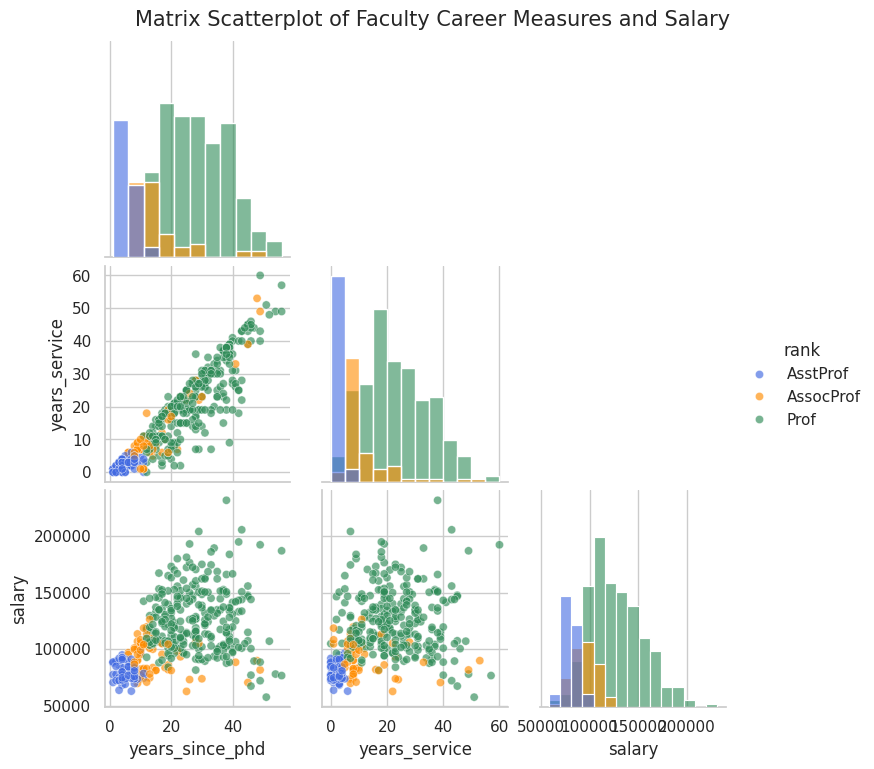

In [14]:
# TODO 3.2: Create and display the matrix scatterplot.
g = sns.pairplot(
    data=df,
    vars=numeric_fields,
    hue="rank",
    hue_order=rank_order,
    palette=rank_palette,
    diag_kind="hist",
    corner=True,
    plot_kws={
        "alpha": 0.65,
        "edgecolor": "white",
        "linewidth": 0.4,
        "s": 35
    },
    diag_kws={
        "alpha": 0.6
    }
)

g.fig.suptitle(
    "Matrix Scatterplot of Faculty Career Measures and Salary",
    y=1.02,
    fontsize=15
)

plt.show()

## **Calculate pairwise correlations**

Calculate and display the correlation matrix for the same numerical fields. Round the results to three decimal places.


In [15]:
# TODO 3.3: Calculate and display the correlation matrix.
correlation_matrix = df[numeric_fields].corr()

print("Pairwise Pearson correlation matrix:")
display(correlation_matrix.round(3))

Pairwise Pearson correlation matrix:


,years_since_phd,years_service,salary
years_since_phd,1.000,0.910,0.419
years_service,0.910,1.000,0.335
salary,0.419,0.335,1.000


### **Task 3 interpretation**

1. Which pair of variables shows the strongest relationship?
2. How does salary appear to relate to the two career measures?
3. Are there visible clusters, unusual observations, or rank differences?
4. What does the chart show that the correlation table does not show?

**Your answer:**  
Write your interpretation here.


The scatterplot matrix displays the relationships between each of the following pairs of variables: years since PhD, years of service, salary. The diagonal histograms display the distribution of each variable, while the scatter plots give the distribution of pairs of variables. Academic ranks are distinguished by colors to make it easier to identify possible rank related clusters. The direction and strength of the linear relationships between the variables are summarized numerically in the correlation matrix, but not as clearly as the plots do. The greatest absolute off-diagonal correlation should be used to identify the strongest relationship. A positive correlation means that the variables go up together and has nothing to do with cause and effect. For better understanding we run the following code:

In [16]:
corr_pairs = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
).stack()

strongest_pair = corr_pairs.abs().idxmax()
strongest_value = corr_pairs.loc[strongest_pair]

print("Strongest pair:", strongest_pair)
print(f"Correlation: {strongest_value:.3f}")

Strongest pair: ('years_since_phd', 'years_service')
Correlation: 0.910


# **Task 4: Trellis plot — 15 points**

Create a trellis scatterplot with:

- `years_since_phd` on the x-axis;
- `salary` on the y-axis;
- one panel for each academic rank;
- marker color based on `sex`;
- Female and Male shown in a fixed legend order;
- shared x-axis and y-axis scales;
- suitable panel titles, axis labels, and a complete figure title.


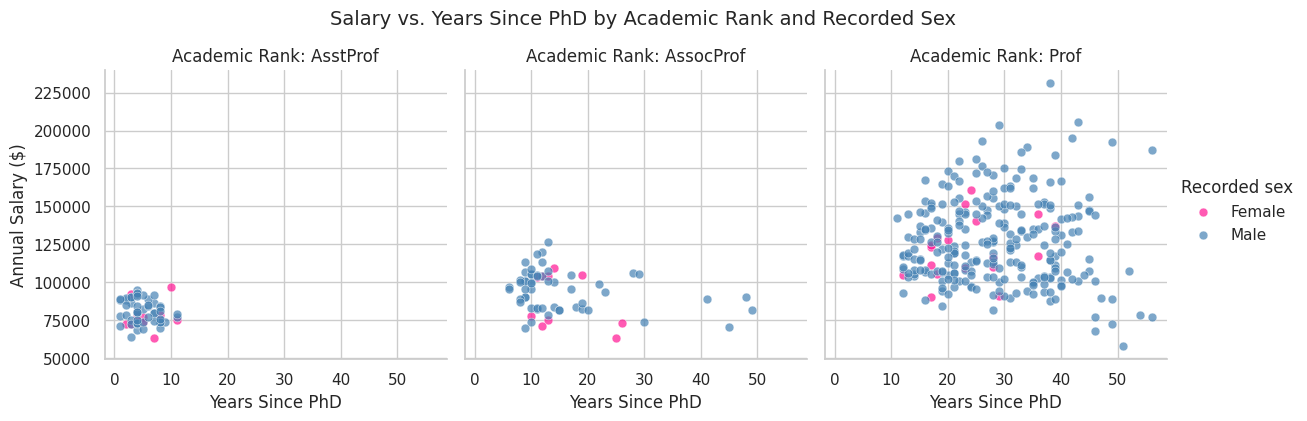

In [17]:
# TODO 4.1: Create and display the trellis plot.
sex_order = ["Female", "Male"]

sex_palette = {
    "Female": "deeppink",
    "Male": "steelblue"
}

g = sns.FacetGrid(
    data=df,
    col="rank",
    col_order=rank_order,
    hue="sex",
    hue_order=sex_order,
    palette=sex_palette,
    sharex=True,
    sharey=True,
    height=4,
    aspect=1
)

g.map_dataframe(
    sns.scatterplot,
    x="years_since_phd",
    y="salary",
    alpha=0.7,
    s=40,
    edgecolor="white",
    linewidth=0.4
)

g.add_legend(title="Recorded sex")

g.set_axis_labels(
    "Years Since PhD",
    "Annual Salary ($)"
)

g.set_titles("Academic Rank: {col_name}")

g.figure.suptitle(
    "Salary vs. Years Since PhD by Academic Rank and Recorded Sex",
    y=1.05,
    fontsize=14
)

plt.show()

## **Check group sizes**

Create and display a rank-by-sex frequency table. Arrange rank rows in their academic order.


In [18]:
# TODO 4.2: Create the rank-by-sex frequency table.
rank_sex_counts = pd.crosstab(
    df["rank"],
    df["sex"]
).reindex(
    index=rank_order,
    columns=sex_order,
    fill_value=0
)

print("Number of records by academic rank and recorded sex:")
display(rank_sex_counts)

Number of records by academic rank and recorded sex:


sex,Female,Male
rank,,
AsstProf,11,56
AssocProf,10,54
Prof,18,248


### **Task 4 interpretation**

1. Does the salary pattern look similar across the rank panels?
2. Which rank has the widest salary variation?
3. How do unequal group sizes affect the appearance of the panels?
4. Why are shared axes important for this comparison?

**Your answer:**  
Write your interpretation here.


The trellis plot is a division of faculty members into panels based on academic hierarchy. For each panel, the x-value indicates years since PhD, the y-value indicates salary, and the color indicates recorded sex. Shared axes enable salary levels and variations to be compared more fairly between ranks. The differences between panels could be due to salary ranges or due to experience in careers. Due to unequal numbers of groups, some groups might be more prominent in the graph or may create more dense areas of points. The frequency table is used to determine if there may be a visual difference that is due to the number of observations in each group. The range of the salaries given in the three panels should be taken to find the maximum difference. A difference between groups, as described only, is descriptive and doesn't (by itself) necessarily explain the difference.

# **Task 5: Bubble plot — 15 points**

Create a bubble plot using:

- x-position: `years_since_phd`;
- y-position: `salary`;
- bubble area: `years_service`;
- bubble color: `rank`.

Requirements:

- use suitable minimum and maximum bubble areas;
- use a fixed size-normalization range;
- apply transparency and visible marker outlines;
- show a brief size and color legend;
- position the legend outside the data area;
- add a title and axis labels.


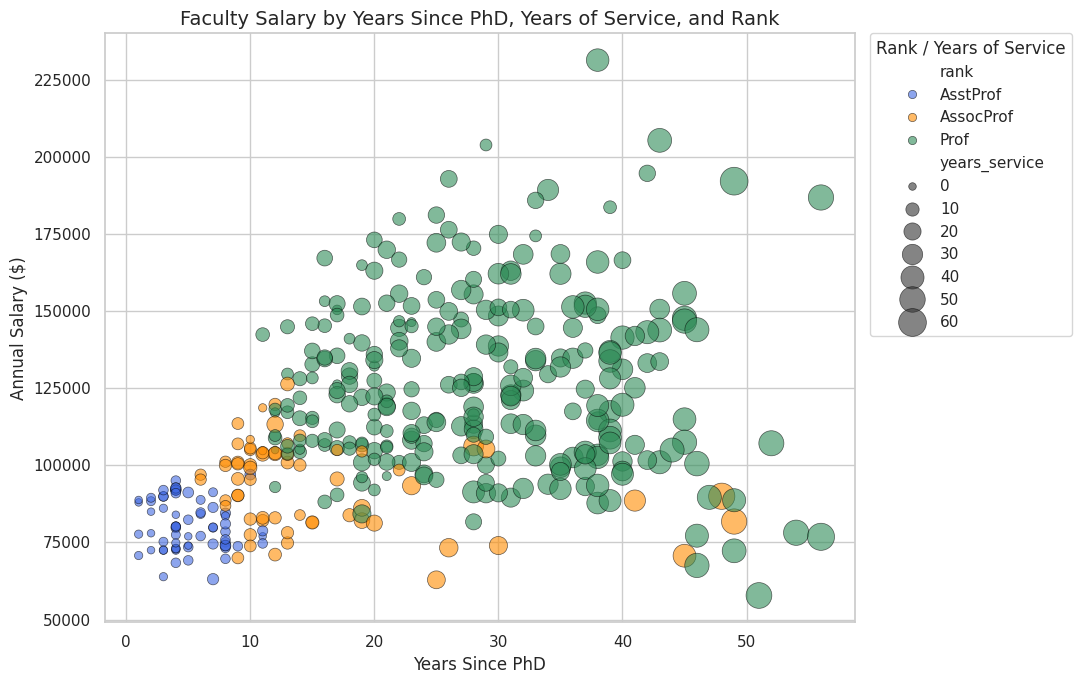

In [19]:
# TODO 5.1: Create and display the bubble plot.
fig, ax = plt.subplots(figsize=(11, 7))

bubble_plot = sns.scatterplot(
    data=df,
    x="years_since_phd",
    y="salary",
    hue="rank",
    hue_order=rank_order,
    palette=rank_palette,
    size="years_service",
    sizes=(30, 400),
    size_norm=(0, 60),
    alpha=0.6,
    edgecolor="black",
    linewidth=0.5,
    legend="brief",
    ax=ax
)

ax.set_title(
    "Faculty Salary by Years Since PhD, Years of Service, and Rank",
    fontsize=14
)
ax.set_xlabel("Years Since PhD")
ax.set_ylabel("Annual Salary ($)")

# Place the combined color and bubble-size legend outside the plot.
ax.legend(
    title="Rank / Years of Service",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    borderaxespad=0
)

plt.tight_layout()
plt.show()

## **Check the relationship between career measures**

Calculate the Pearson correlation between `years_since_phd` and `years_service`. Display three decimal places.


In [20]:
# TODO 5.2: Calculate and display the career-measure correlation.
career_correlation = df[
    ["years_since_phd", "years_service"]
].corr().iloc[0, 1]

print(
    "Pearson correlation between years since PhD "
    f"and years of service: {career_correlation:.3f}"
)

Pearson correlation between years since PhD and years of service: 0.910


### **Task 5 interpretation**

1. What information does bubble area add?
2. Are years since PhD and years of service strongly related?
3. Does bubble size provide independent information from the x-position?
4. What problem occurs when large bubbles cover smaller observations?

**Your answer:**  
Write your interpretation here.


Bubble size adds a third variable years of service to the relationship between years since PhD and salary. Academic rank is indicated by the color of the bubbles. The Pearson correlation shows the degree of linear association between the two measures of a career. Because years of service and years since PhD may overlap in the information they convey, bubble size might not add entirely independent information. Faculty members with the same number of years since the PhD, however, may have different amounts of service. This is not ideal since large bubbles may obscure smaller observations and thus make some records hard to see. This can be minimized by using transparency and marker outlines but not eliminated.

# **Task 6: Contour plot — 20 points**

Use only records where `rank == "Prof"`.


In [21]:
# TODO 6.1: Create the Professor-only DataFrame and display its size.
professors = df.loc[
    df["rank"] == "Prof"
].copy()

print("Number of Professor records:", len(professors))
print("Professor DataFrame shape:", professors.shape)

display(professors.head())

Number of Professor records: 266
Professor DataFrame shape: (266, 6)


,rank,discipline,years_since_phd,years_service,sex,salary
0,Prof,B,19,18,Male,139750
1,Prof,B,20,16,Male,173200
3,Prof,B,45,39,Male,115000
4,Prof,B,40,41,Male,141500
6,Prof,B,30,23,Male,175000


## **Create the model inputs**

Use:

- `years_since_phd` and `years_service` as predictors stored in `X`;
- `salary` as the outcome stored in `y`.

Convert both objects to NumPy arrays and display their shapes.


In [22]:
# TODO 6.2: Create X and y and display their shapes.
X = professors[
    ["years_since_phd", "years_service"]
].to_numpy()

y = professors["salary"].to_numpy()

print("X shape (predictors):", X.shape)
print("y shape (salary outcome):", y.shape)

X shape (predictors): (266, 2)
y shape (salary outcome): (266,)


## **Fit and inspect the model**

Fit a `LinearRegression` model. Display:

- the intercept;
- both predictor coefficients;
- the model's R² value.


In [23]:
# TODO 6.3: Create and fit the LinearRegression model.
model = LinearRegression()
model.fit(X, y)

print("Linear regression model fitted successfully.")

Linear regression model fitted successfully.


In [24]:
# TODO 6.4: Display the intercept, coefficients, and R-squared value.
print(f"Intercept: ${model.intercept_:,.2f}")

print(
    "Coefficient for years since PhD: "
    f"${model.coef_[0]:,.2f}"
)

print(
    "Coefficient for years of service: "
    f"${model.coef_[1]:,.2f}"
)

r_squared = model.score(X, y)

print(f"R-squared: {r_squared:.3f}")

Intercept: $124,927.95
Coefficient for years since PhD: $397.24
Coefficient for years of service: $-411.92
R-squared: 0.009


## **Create the prediction grid**

1. Create 90 evenly spaced coordinates across the observed range of each predictor.
2. Use `np.meshgrid()` to construct the two-dimensional coordinate grids.
3. Flatten and combine the two grids into prediction rows.
4. Display the shape of the prediction grid.


In [25]:
# TODO 6.5: Create the two coordinate arrays.
phd_values = np.linspace(
    professors["years_since_phd"].min(),
    professors["years_since_phd"].max(),
    90
)

service_values = np.linspace(
    professors["years_service"].min(),
    professors["years_service"].max(),
    90
)

print("Number of PhD coordinates:", len(phd_values))
print("Number of service coordinates:", len(service_values))

Number of PhD coordinates: 90
Number of service coordinates: 90


In [26]:
# TODO 6.6: Create the mesh grids and prediction grid.
phd_grid, service_grid = np.meshgrid(
    phd_values,
    service_values
)

prediction_grid = np.column_stack([
    phd_grid.ravel(),
    service_grid.ravel()
])

print("PhD grid shape:", phd_grid.shape)
print("Service grid shape:", service_grid.shape)
print("Prediction grid shape:", prediction_grid.shape)

PhD grid shape: (90, 90)
Service grid shape: (90, 90)
Prediction grid shape: (8100, 2)


## **Predict salary across the grid**

Use the fitted model to predict salary for every grid row. Reshape the predictions to match the coordinate-grid shape.


In [27]:
# TODO 6.7: Calculate and reshape the grid predictions.
salary_predictions = model.predict(prediction_grid)

salary_grid = salary_predictions.reshape(
    phd_grid.shape
)

print("Salary prediction grid shape:", salary_grid.shape)

Salary prediction grid shape: (90, 90)


## **Create the contour visualization**

Your visualization must include:

- filled contour bands;
- contour lines;
- currency labels on the contour lines;
- overlaid Professor observations;
- a labeled color bar;
- a title and axis labels.


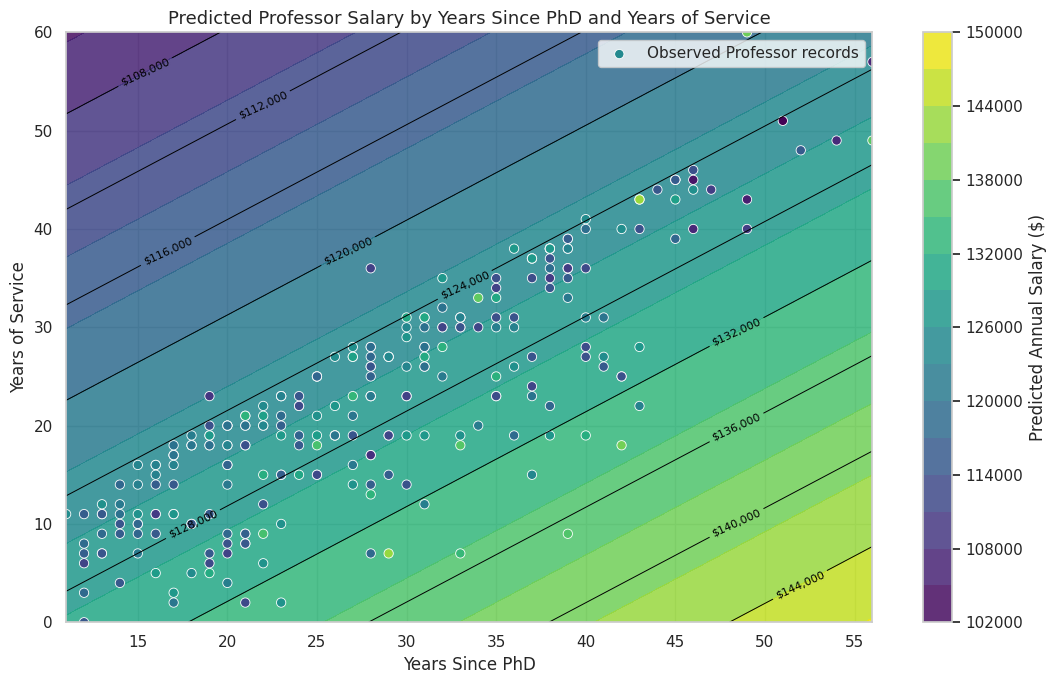

In [28]:
# TODO 6.8: Create and display the completed contour plot.
fig, ax = plt.subplots(figsize=(11, 7))

# Filled contour bands show predicted salary levels.
filled_contours = ax.contourf(
    phd_grid,
    service_grid,
    salary_grid,
    levels=15,
    cmap="viridis",
    alpha=0.85
)

# Contour lines show locations with equal predicted salary.
contour_lines = ax.contour(
    phd_grid,
    service_grid,
    salary_grid,
    levels=10,
    colors="black",
    linewidths=0.7
)

# Label contour lines with predicted salary values.
ax.clabel(
    contour_lines,
    inline=True,
    fontsize=8,
    fmt=lambda value: f"${value:,.0f}"
)

# Overlay the observed Professor records.
observations = ax.scatter(
    professors["years_since_phd"],
    professors["years_service"],
    c=professors["salary"],
    cmap="viridis",
    edgecolor="white",
    linewidth=0.6,
    s=45,
    label="Observed Professor records"
)

# Add a color bar for predicted salary.
colorbar = fig.colorbar(
    filled_contours,
    ax=ax
)
colorbar.set_label("Predicted Annual Salary ($)")

ax.set_title(
    "Predicted Professor Salary by Years Since PhD and Years of Service",
    fontsize=13
)
ax.set_xlabel("Years Since PhD")
ax.set_ylabel("Years of Service")
ax.legend(loc="best")

plt.tight_layout()
plt.show()

### **Task 6 interpretation**

1. What does each contour line represent?
2. What do the colored regions represent?
3. Why are the observed records overlaid on the prediction surface?
4. Which areas have sparse data coverage?
5. What does the R² value suggest about the model's explanatory strength?
6. Does the surface prove that career experience causes salary differences? Explain.

**Your answer:**  
Write your interpretation here.


The contour lines join values of combinations of years since PhD and years of service that yield the same salary as predicted by the linear regression model fitted to these data. The filled colors show the different salary level predictions, and the colors on the bar show the values of the salary level predictions. The fitted surface is overlaid on the observed Professor records so it can be compared with the actual distribution of the data. Predicting outside of areas with few or no observations, especially close to the edges of the range of the predictors, is less well supported by the data and should be done with caution. The R-squared value indicates the percentage of the variation in the observed salaries accounted for by the fitted model in this sample. A higher number means that the model fits the data well, but it does not mean that the model is complete and accurate for other samples. The surface presents associations, rather than proof of the influence of career experience on salary differences.

# **Task 7: Chart comparison and conclusion - 15 points**

Complete the following table.

| Chart | Variables represented | Visual channels | Main advantage | Main limitation |
|---|---|---|---|---|
| Matrix scatterplot | Years since PhD, years of service, salary, and academic rank | X- and y-position, color, and diagonal histograms | Shows pairwise relationships, distributions, clusters, and potential outliers in one figure | Can become crowded when many observations overlap |
| Trellis plot | Years since PhD, salary, academic rank, and recorded sex | X- and y-position, separate panels, and color | Makes it easier to compare salary patterns across academic ranks and recorded sex categories | Unequal group sizes and overlapping points can make comparisons difficult |
| Bubble plot | Years since PhD, years of service, salary, and academic rank | X- and y-position, bubble area, and color | Displays four variables in one chart and shows differences in service among faculty members | Large bubbles can obscure smaller observations, and bubble areas are harder to compare precisely |
| Contour plot | 	Years since PhD, years of service, and predicted salary for Professors | X- and y-position, filled color regions, and contour lines | Shows the model's predicted salary surface across combinations of two career measures | Predictions depend on the fitted model and may be unreliable where observations are sparse |


## **Conclusion**

Write approximately 150–200 words explaining:

- the most important relationship you found;
- which chart communicated it most clearly;
- how rank or recorded sex affected the analysis;
- why group size and data coverage matter;
- why the results describe associations rather than causal effects.

**Your conclusion:**  
Write your paragraph here.


Multiple visualizations were used in this assignment to explore the relationships between academic rank, recorded sex, years since PhD, years of service and salary. The matrix scatter graph was used to compare the numerical variables and to see if there were any patterns, clusters and anything unusual. Comparing salary patterns across academic ranks was easier with a trellis plot, and sex categories were shown with separate panels, on the same axes. The bubble plot included a third visual dimension, that of "Years of service," and the contour plot visually represented the salary predictions based on a linear regression model for Professors. Each chart offered a unique view but the matrix scatter plot was especially helpful to investigate multiple relationships between pairs. Other dimensions for comparison across groups were academic rank and recorded sex. However, group size is important because unequal numbers of observations can influence the density and/or convincingness of a pattern. Data coverage is important also because the areas with few observations may be unreliable for model predictions. Lastly, correlations and regression results only describe the relationship of data available and do not establish a cause-effect relationship. The results should be used with caution as other factors could affect salary and the findings should not be interpreted as a statement that career experience is the only determinant for salary.